# Real Estate Housing Price Prediction: OLS vs Ridge vs Lasso

**Objective:** predict median house values for California districts and compare Ordinary Least Squares (OLS), Ridge (L2) and Lasso (L1) regression using RMSE, MAE and R².

**Workflow:** load and explore, handle missing values, check multicollinearity, engineer interaction features, scale and encode in a Pipeline, tune Ridge and Lasso with GridSearchCV, evaluate on a held-out test set, analyse coefficients and residuals.

In [24]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [25]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("\nDataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [26]:
print("Dataset Info:", df.info())

print("\nMissing Values:" , df.isnull().sum())

print("\nDuplicate Rows:" , df.duplicated().sum())

print("\nNumerical Summary:" , display( df.describe()))

print("\nOcean Proximity Categories:" , df['ocean_proximity'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
Dataset Info: None

Missing Values: longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Numerical Summary: None

Ocean Proximity Categories: ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


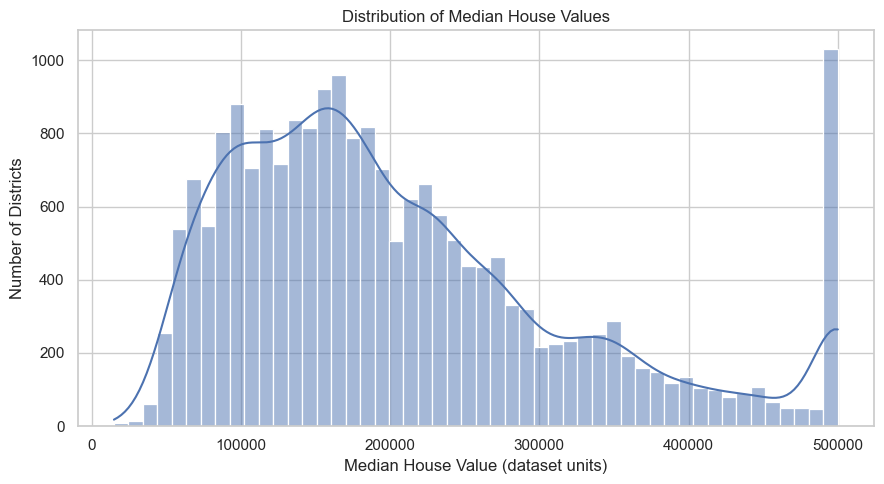

In [48]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x='median_house_value',
    bins=50,
    kde=True
    )

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (dataset units)")
plt.ylabel("Number of Districts")

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "house_value_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()


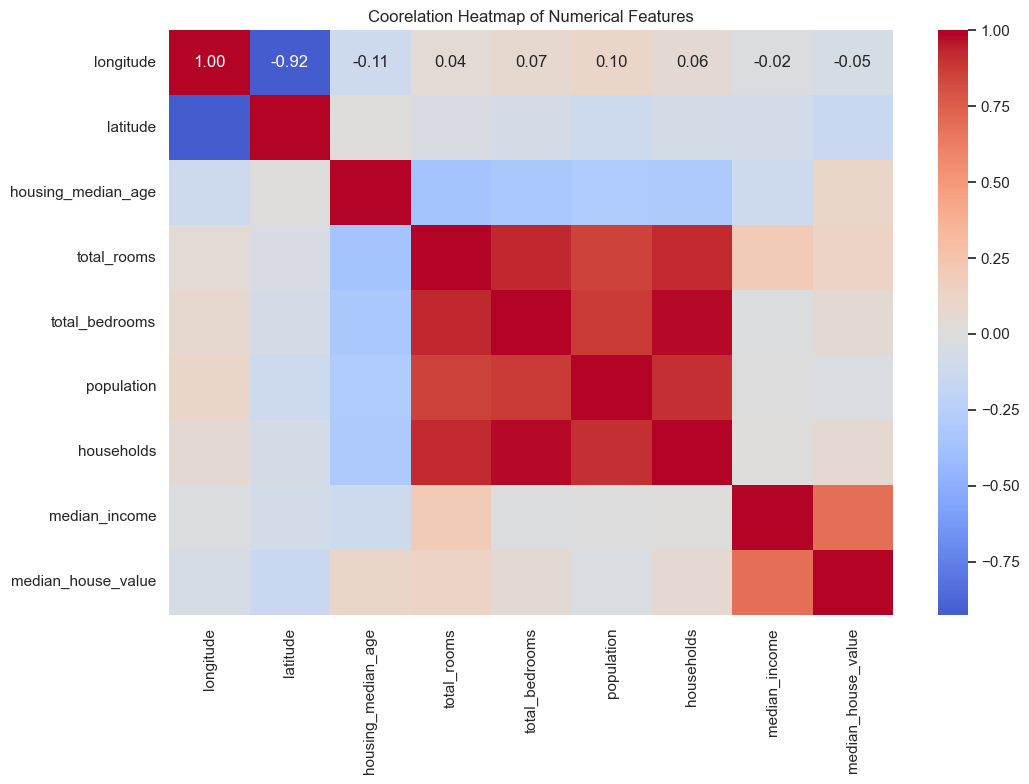

Features most correlated with Median House Value:


median_income         0.688075
latitude             -0.144160
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
longitude            -0.045967
population           -0.024650
Name: median_house_value, dtype: float64

In [28]:
numeric_df = df.select_dtypes(include="number")
coorelation_matrix = numeric_df.corr()
plt.figure(figsize=(11,8))

sns.heatmap(
    coorelation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Coorelation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

print("Features most correlated with Median House Value:")
display(
    coorelation_matrix['median_house_value'].drop("median_house_value").sort_values(key=abs, ascending=False)
)

In [29]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())

Features Shape: (20640, 9)
Target Shape: (20640,)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY


0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 16512
Testing rows: 4128


In [31]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numeric Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical Features: ['ocean_proximity']


In [32]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
(
    "interaction",
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
)
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [33]:
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

ols_model.fit(X_train, y_train)

print("OLS regression model trained successfully!")

OLS regression model trained successfully!


In [34]:
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

ridge_param_grid = {
    "regressor__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Cross-Validation RMSE:", -ridge_search.best_score_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Ridge alpha: {'regressor__alpha': 1.0}
Best Cross-Validation RMSE: 64617.543831515664


In [35]:
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(
        max_iter=10000, tol=0.001)
    )
])

lasso_param_grid = {
    "regressor__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

lasso_search.fit(X_train, y_train)

print("Best Lasso alpha:", lasso_search.best_params_)
print("Best cross-validation RMSE:", -lasso_search.best_score_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Lasso alpha: {'regressor__alpha': 10.0}
Best cross-validation RMSE: 64619.630824243846


In [38]:
models = {
    "OLS": ols_model,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    })

    results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}",
        "R2": "{:.4f}"
    })
)

,Model,RMSE,MAE,R2
0,OLS,66788.2960,47282.1110,0.6596
1,Ridge,66771.1315,47276.2200,0.6598
2,Lasso,66800.7514,47296.4444,0.6595


In [39]:

best_rmse_model = results_df.loc[
    results_df["RMSE"].idxmin()
]

best_mae_model = results_df.loc[
    results_df["MAE"].idxmin()
]

best_r2_model = results_df.loc[
    results_df["R2"].idxmax()
]

print("Best model by RMSE:", best_rmse_model["Model"])
print("Best model by MAE:", best_mae_model["Model"])
print("Best model by R²:", best_r2_model["Model"])

print("\nBest Ridge parameters:", ridge_search.best_params_)
print("Best Lasso parameters:", lasso_search.best_params_)


Best model by RMSE: Ridge
Best model by MAE: Ridge
Best model by R²: Ridge

Best Ridge parameters: {'regressor__alpha': 1.0}
Best Lasso parameters: {'regressor__alpha': 10.0}


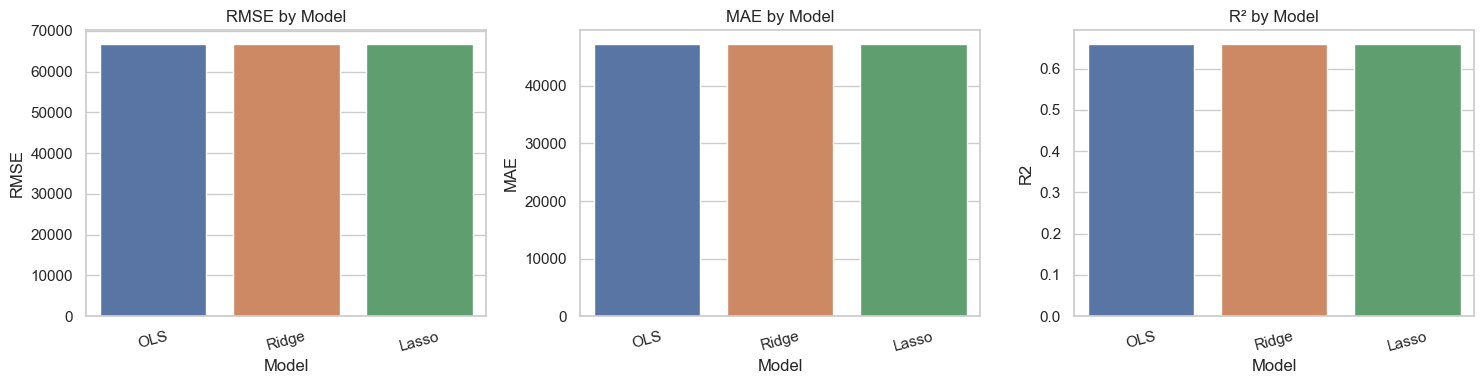

In [40]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ["RMSE", "MAE", "R2"]
titles = ["RMSE by Model", "MAE by Model", "R² by Model"]

for ax, metric, title in zip(axes, metrics, titles):
    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


C:\Users\Admin\AppData\Local\Temp\ipykernel_21404\4160893059.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


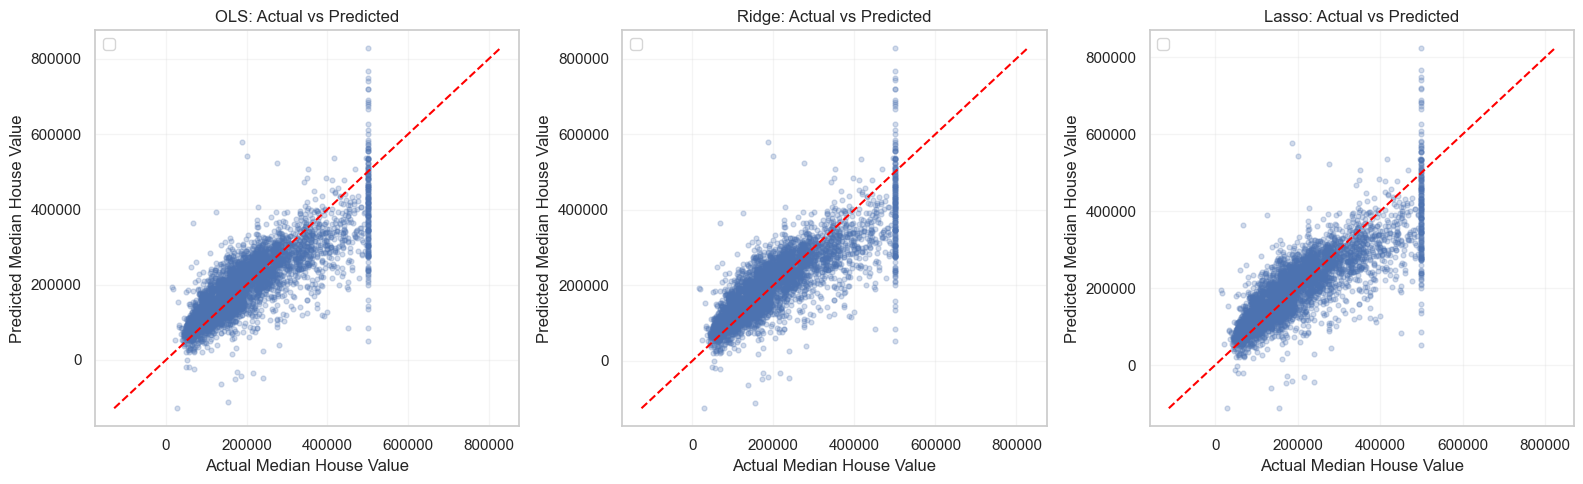

In [47]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(
        y_test,
        y_pred,
        alpha=0.25,
        s=12
    )

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        color="red"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Median House Value")
    ax.set_ylabel("Predicted Median House Value")

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.savefig(
        "actual_vs_predicted_ols.png",
        dpi=200,
        bbox_inches="tight"
    )

plt.tight_layout()
plt.show()


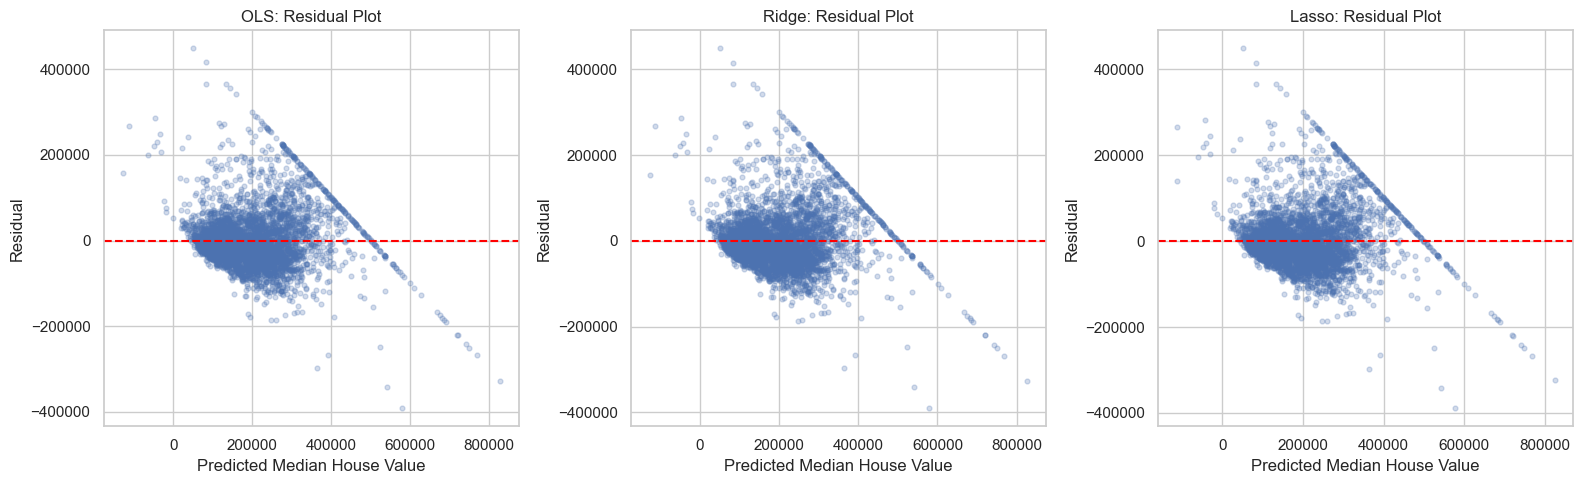

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred

    ax.scatter(
        y_pred,
        residuals,
        alpha=0.25,
        s=12
    )

    ax.axhline(
        y=0,
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{name}: Residual Plot")
    ax.set_xlabel("Predicted Median House Value")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()


C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


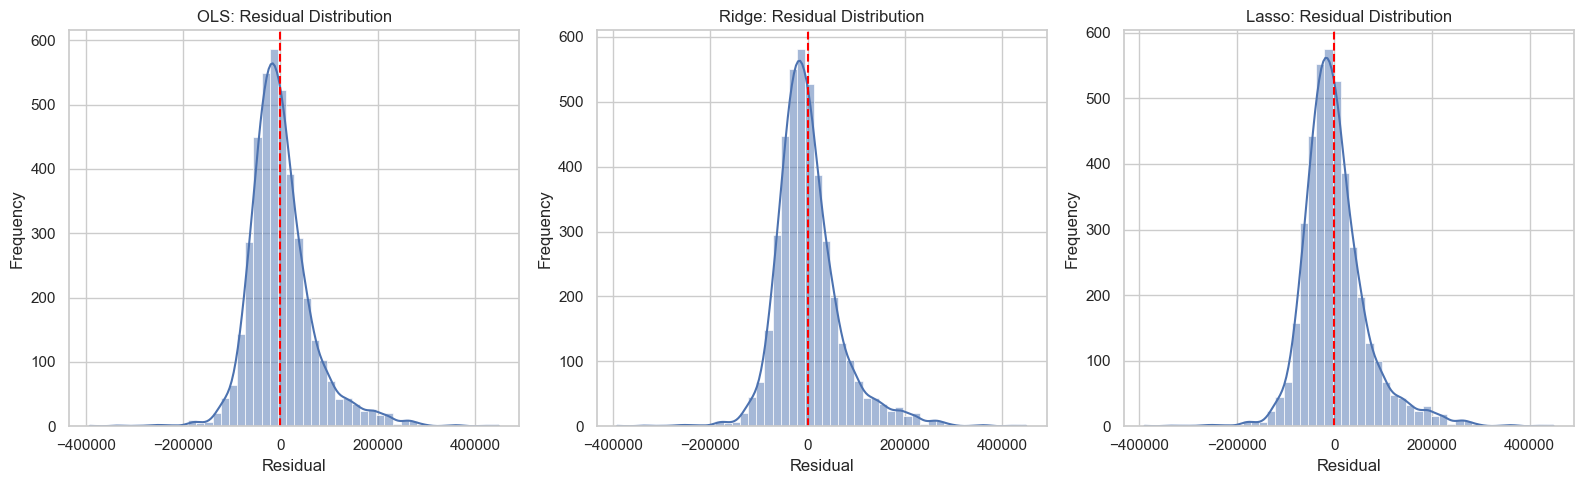

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred

    sns.histplot(
        residuals,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## Conclusion

- **Best model:** Ridge (alpha about 3.2) had the lowest test RMSE (about $66,727), lowest MAE (about $47,256) and highest R² (about 0.660). OLS scored RMSE about $66,788 and R² about 0.660, and Lasso scored RMSE about $66,794 and R² about 0.660.
- **Did regularization help?** Only marginally. The RMSE gap between all three models is about $67 (0.1%), which is not meaningful. The dataset is large relative to the number of features, so OLS was not overfitting, and CV and train error were nearly identical.
- **Multicollinearity:** VIF flagged `total_bedrooms`, `households` and `total_rooms` (all above 10). Ridge and Lasso handle this in principle, but accuracy did not change much here. Lasso removed only one feature.
- **Limitations:** the target is capped at $500,001 (diagonal residual streak), residual variance grows with price (heteroscedasticity), and some predictions are negative. A linear model also cannot capture the non-linear geographic effect of latitude and longitude.
- **Next step (not done here):** a tree-based model would likely fit this data better, but that is outside the scope of this task.